### 04. Subgroup SHAP Analysis

This notebook investigates whether the explainability findings from
notebook 03 help explain the subgroup-specific results from notebook 02.
Specifically, notebook 02 found that the learned correction significantly
improves classification for Normal EF but not for HFrEF or HFmrEF, while
notebook 03 found that volume_ratio — the dominant predictor — has a
non-monotonic effect on the correction, peaking around 0.4-0.5 and
diminishing at both extremes.

This notebook tests whether patients in different clinical categories fall
into different regions of that curve, which would offer a mechanistic
explanation for why the correction helps some categories more than others.

Given the small sample size for HFmrEF (n≈8 in TEST), formal statistical
comparison is restricted to Normal EF vs. HFrEF; HFmrEF is included only
descriptively.

All analyses are performed on the **TEST split**, consistent with
notebooks 02 and 03.

- **Inputs:** `models/gb_correction.joblib`, `data/processed/inference_with_corrections.csv`
 - **Outputs:** Subgroup dependence plot saved to `figures/`.
  Descriptive statistics and Mann-Whitney test results are
  displayed in the notebook.

#### Load model, data, and clinical classes

In [5]:
import sys

import pandas as pd
import joblib
import numpy as np
import shap
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", font_scale=1.0)

reg = joblib.load("../models/gb_correction.joblib")
data = pd.read_csv("../data/processed/inference_with_corrections.csv")

test = data[data['split'] == 'TEST'].copy()
features = ['volume_ratio', 'length_ratio', 'dice_overlap_std']
X_test = test[features]

def classify_ef(ef):
    if ef <= 40:
        return 'HFrEF'
    elif ef < 50:
        return 'HFmrEF'
    elif ef < 75:
        return 'Normal'
    else:
        return 'HCM'

test['true_class'] = test['true_ef'].apply(classify_ef)
test['true_class'].value_counts()

true_class
Normal    329
HFrEF      27
HFmrEF     12
Name: count, dtype: int64

Sample sizes are highly imbalanced across categories (Normal: n=333,
HFrEF: n=27, HFmrEF: n=8). Comparisons involving HFrEF should be
interpreted as exploratory given its limited sample size, and HFmrEF
(n=8) is excluded from formal statistical testing entirely, as noted
above. This does not invalidate the comparison but confidence in the HFrEF result is
necessarily lower than in Normal EF.

#### Volume ratio dependence by clinical category

The dependence plot for volume_ratio (notebook 03) showed a non-monotonic
effect: strongly negative SHAP values for low ratios, a positive plateau
around 0.4-0.5, and a decline for higher ratios. Here, the same plot is
recolored by true clinical category instead of by feature interaction, to
check whether patients from different categories fall into different
regions of this curve.

Sample sizes are highly imbalanced (Normal: n=333, HFrEF: n=27,
HFmrEF: n=8); HFrEF and especially HFmrEF results should be read as
exploratory.

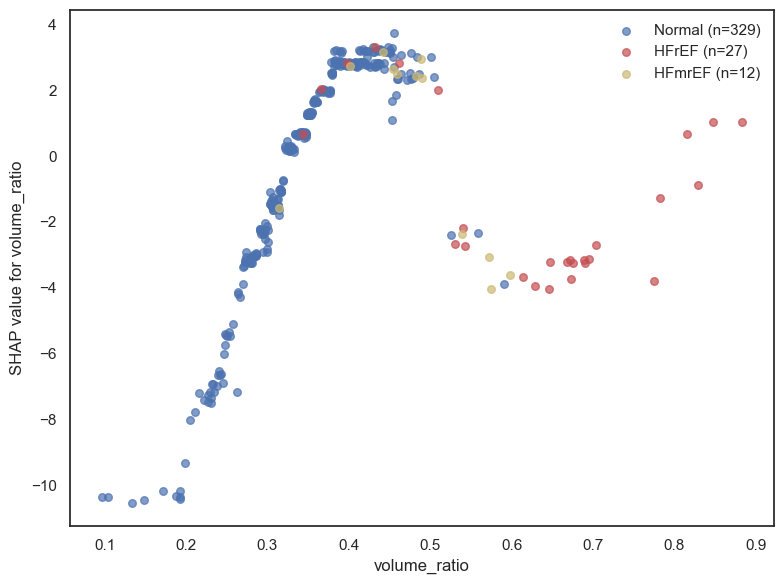

In [6]:
explainer = shap.TreeExplainer(reg)
shap_values = explainer.shap_values(X_test)

shap_volume = shap_values[:, features.index('volume_ratio')]
volume_ratio_vals = X_test['volume_ratio'].values

palette = {'Normal': '#4C72B0', 'HFrEF': '#C44E52', 'HFmrEF': '#CCB974', 'HCM': '#55A868'}

fig, ax = plt.subplots(figsize=(8, 6))
for cls in ['Normal', 'HFrEF', 'HFmrEF', 'HCM']:
    mask = test['true_class'].values == cls
    if mask.sum() == 0:
        continue
    ax.scatter(
        volume_ratio_vals[mask], shap_volume[mask],
        label=f'{cls} (n={mask.sum()})',
        color=palette[cls], alpha=0.7, s=30
    )

ax.set_xlabel('volume_ratio')
ax.set_ylabel('SHAP value for volume_ratio')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig('../figures/shap_volume_by_class.png', dpi=200, bbox_inches='tight')
plt.show()

In [7]:
test.groupby('true_class')['volume_ratio'].describe()[['count', 'mean', '25%', '50%', '75%']]

,count,mean,25%,50%,75%
true_class,,,,,
HFmrEF,12.0,0.484728,0.451372,0.486050,0.547454
HFrEF,27.0,0.631870,0.535153,0.668276,0.699468
Normal,329.0,0.347992,0.303759,0.347681,0.400176


The median volume_ratio differs across EF categories, with Normal
cases showing lower values than HFmrEF and HFrEF. The scatter plot
also suggests that these categories occupy different regions of
the volume_ratio–SHAP relationship.

In particular, Normal cases are more concentrated around the
intermediate range of volume_ratio, whereas HFrEF cases tend to
show higher values. These differences indicate that the model
assigns different contributions to volume_ratio across the
observed patient groups.

However, SHAP values describe feature contributions to the
predicted correction, not model uncertainty or reliability.
Therefore, these patterns alone do not establish that the model
is less reliable for HFrEF cases.

#### Statistical comparison: SHAP distributions (Normal vs. HFrEF)

To formally test whether the SHAP value distribution for volume_ratio
differs between Normal and HFrEF patients, a Mann-Whitney U test is used
(non-parametric, appropriate given no normality assumption and unequal
group sizes). HFmrEF (n=8) is excluded from formal testing due to its
very small sample size; it is reported descriptively only.

- **H0:** The SHAP values for Normal and HFrEF cases show no
  statistically significant difference in their distributions.
- **H1:** The SHAP value distributions differ between the two groups.
- **Significance level:** α = 0.05.

In [8]:
from scipy.stats import mannwhitneyu

shap_normal = shap_volume[test['true_class'].values == 'Normal']
shap_hfref = shap_volume[test['true_class'].values == 'HFrEF']
shap_hfmref = shap_volume[test['true_class'].values == 'HFmrEF']

stat, p_value = mannwhitneyu(shap_normal, shap_hfref, alternative='two-sided')

print(f"Normal median SHAP: {np.median(shap_normal):.3f}")
print(f"HFrEF median SHAP:  {np.median(shap_hfref):.3f}")
print(f"HFmrEF median SHAP (descriptive only, n=8): {np.median(shap_hfmref):.3f}")
print(f"\nMann-Whitney U = {stat:.1f}, p = {p_value:.4f}")
print("reject H0" if p_value < 0.05 else "-> fail to reject H0")

Normal median SHAP: 0.693
HFrEF median SHAP:  -2.710
HFmrEF median SHAP (descriptive only, n=8): 2.401

Mann-Whitney U = 5899.0, p = 0.0046
reject H0


The Mann-Whitney U test indicates a statistically significant
difference in the SHAP value distributions for volume_ratio
between Normal and HFrEF cases.

The median SHAP values provide a descriptive indication of
the direction of this difference. These results suggest that
volume_ratio contributes differently to the predicted correction
across the two groups.

Nevertheless, the statistical difference in SHAP values does
not establish that this feature explains the differences in
classification performance observed in notebook 02.

#### Conclusions

The subgroup analysis reveals differences in how volume_ratio
contributes to the predicted correction across EF categories.
Normal EF cases tend to occupy lower volume_ratio ranges and
show more positive SHAP contributions, whereas HFrEF cases
are more concentrated at higher volume_ratio values, with
more negative contributions.

The Mann-Whitney U test provides statistical evidence of a
difference in the SHAP value distributions between Normal
and HFrEF cases (p = 0.0046). These findings
suggest that the contribution of volume_ratio to the
correction model varies across EF categories.

This pattern provides a possible interpretation of the
subgroup-specific classification results observed in
notebook 02, where the correction improved Normal EF
classification more consistently than HFrEF classification.
However, the observed differences do not establish a causal
relationship or demonstrate that the model is less reliable
for HFrEF cases.

HFmrEF findings remain descriptive due to the limited sample
size. Overall, this analysis highlights differences in the
model's feature contributions across EF categories, while
providing exploratory evidence of their relationship with
the observed classification performance.